In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '1'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [3]:
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from utils.linear_model import get_ODR, get_OLS

In [4]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = 10**np.random.normal(0, 0.3, N) - 1
y = k * x + b + np.random.normal(0, sig, N)

y_err = np.abs(y) / np.random.uniform(2, 4, size=N)
y_obs = y + np.random.normal(0, y_err, N)

x_err = np.abs(x) / np.random.uniform(3, 5, size=N)
x_obs = x + np.random.normal(0, x_err, N)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

In [5]:
res_ODR = get_ODR(x_obs, y_obs)
res_wODR = get_ODR(x_obs, y_obs, x_err=x_err, y_err=y_err)
res_OLS = get_OLS(x_obs, y_obs)

2024-11-01 11:08:04.428211: W external/xla/xla/service/gpu/nvptx_compiler.cc:765] The NVIDIA driver's CUDA version is 12.4 which is older than the ptxas CUDA version (12.6.77). Because the driver is older than the ptxas version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.


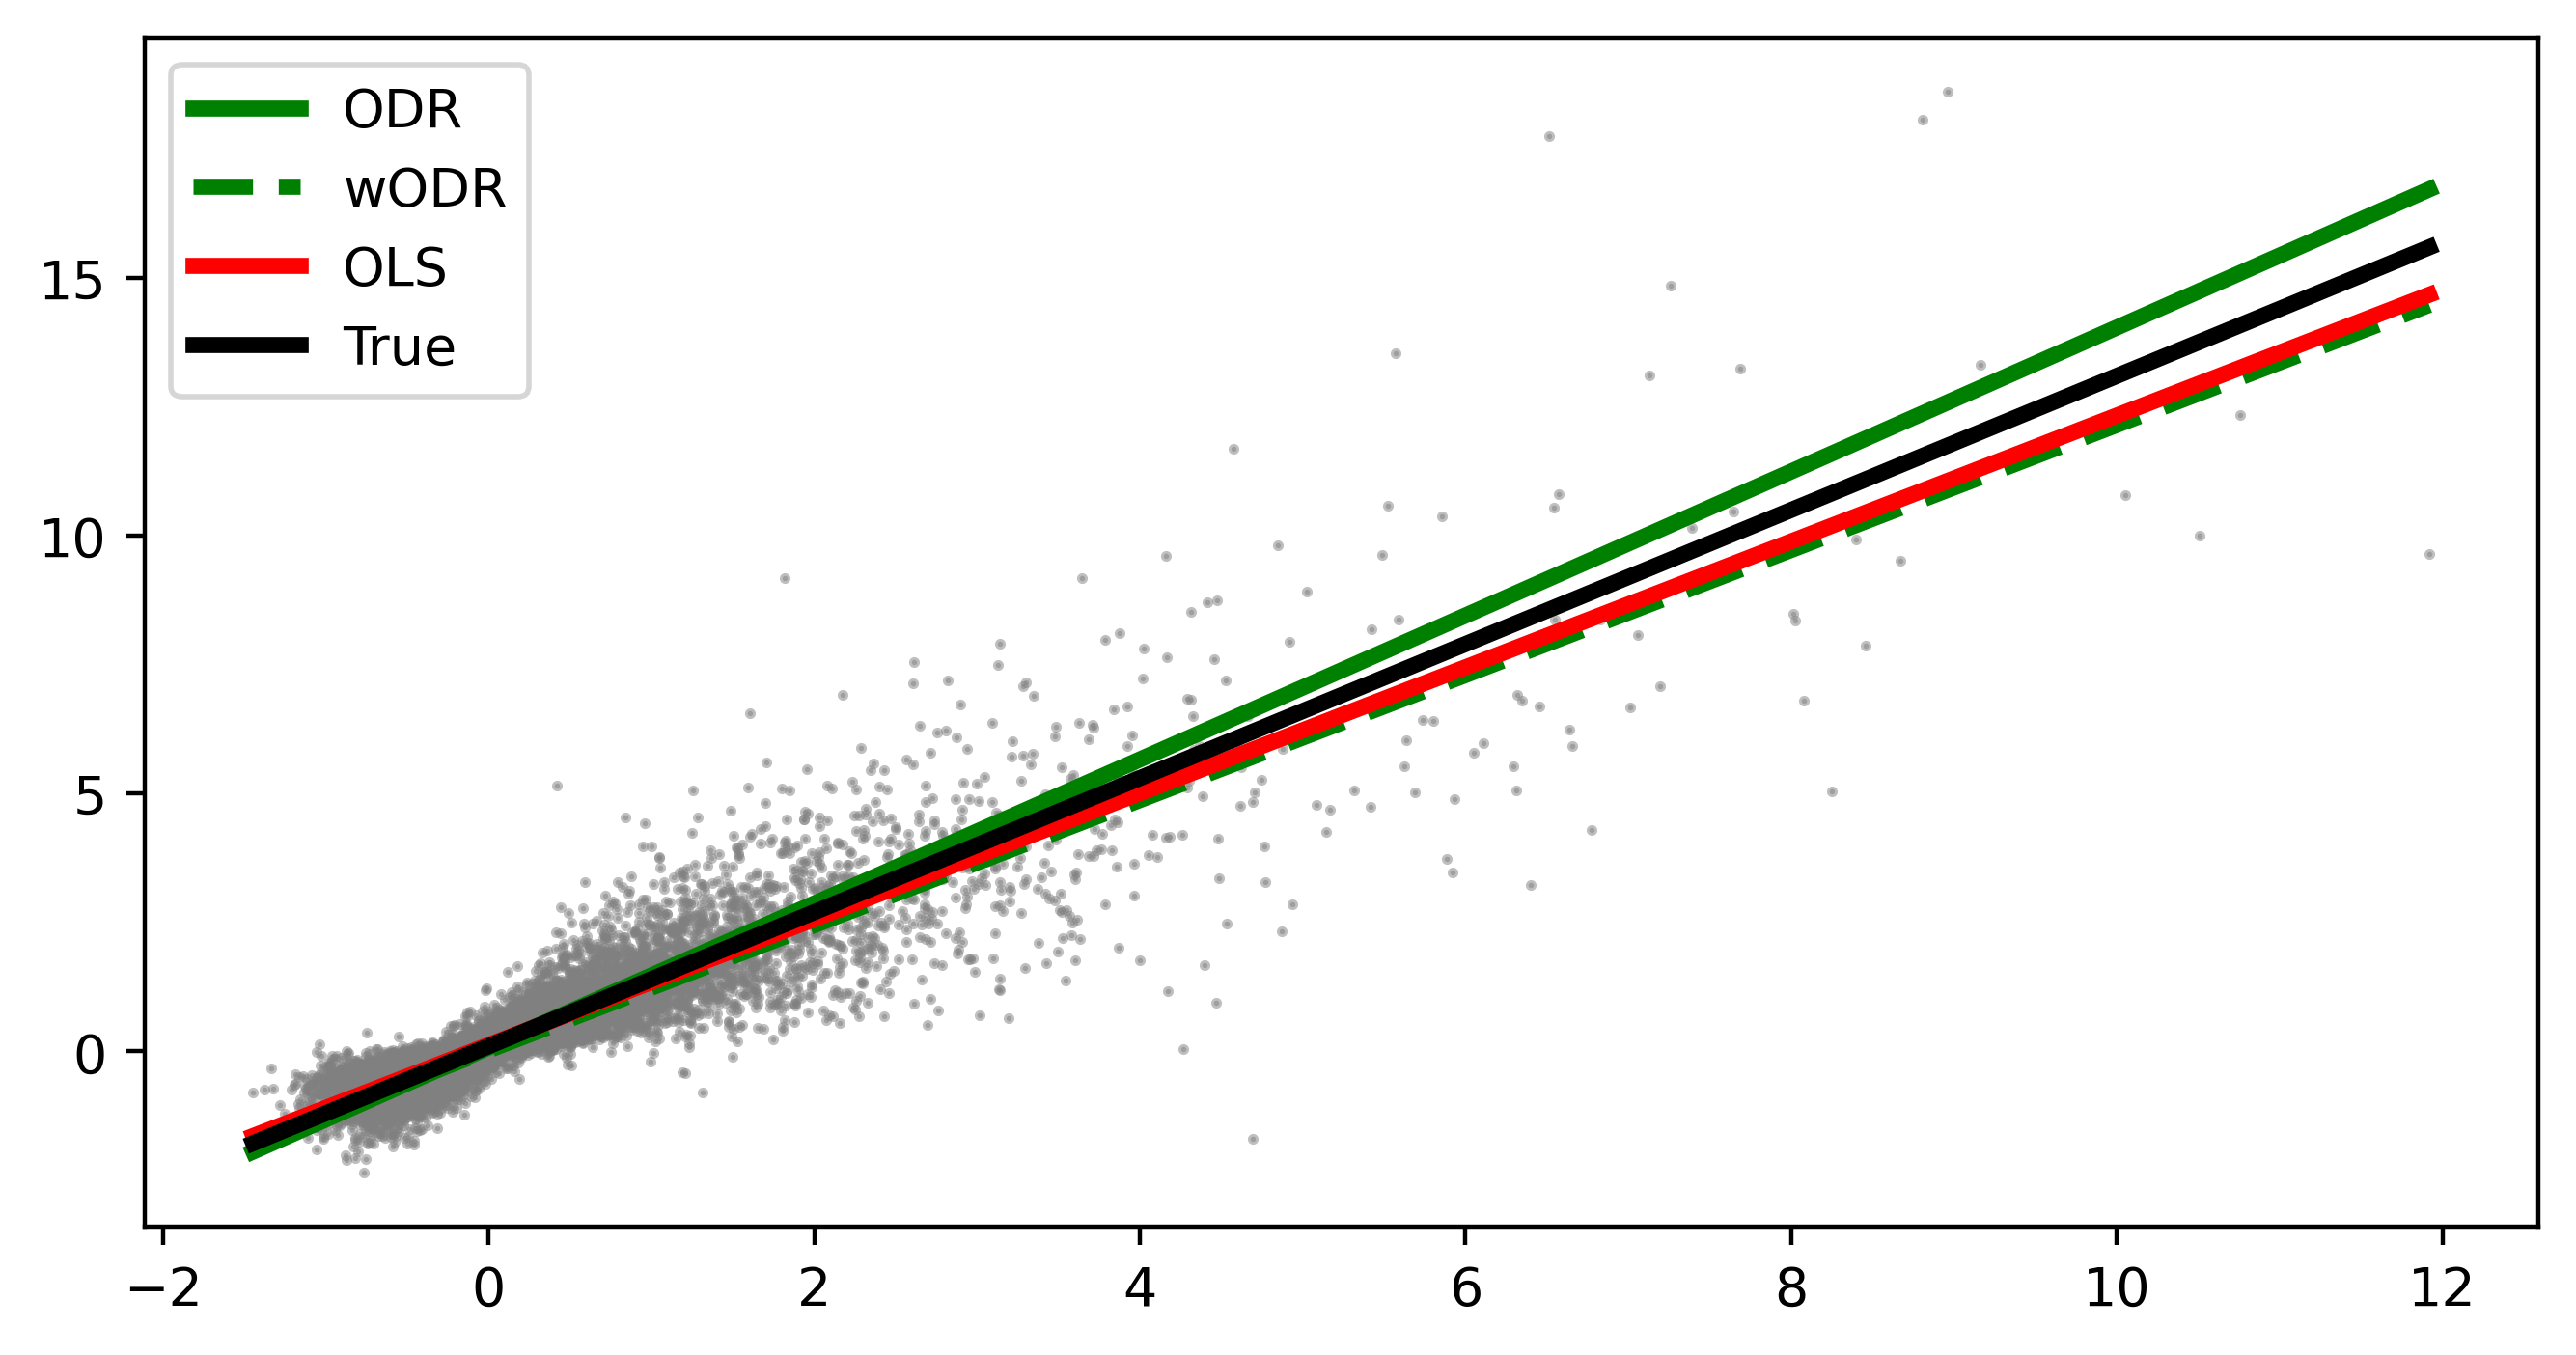

In [6]:
plt.figure(figsize=(8, 4), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(x_obs.min(), x_obs.max(), 100)
yy = k * xx + b
yy_ODR = res_ODR['func_xy'](xx)
yy_wODR = res_wODR['func_xy'](xx)
yy_OLS = res_OLS['func'](xx)

plt.plot(xx, yy_ODR, color='green', label='ODR', linestyle='-', lw=3)
plt.plot(xx, yy_wODR, color='green', label='wODR', linestyle='--', lw=3)
plt.plot(xx, yy_OLS, color='red', label='OLS', linestyle='-', lw=3)
plt.plot(xx, yy, color='black', label='True', lw=3)

plt.legend()

### Fit p(x, x_err) and p(y, y_err)

In [ ]:
from raddest.api.fitter import FlowVI, RegressorLinearML, RegressorLinearKS

In [ ]:
xflow = FlowVI(x_min=x_obs.min(),
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=None)

xflow.fit(x_obs, x_err, verbose=True, n_pre=100, max_stuck=10, stuck_frac=0.02)

100%|██████████| 100/100 [00:04<00:00, 20.64it/s]


step 0: loss 0.7278528213500977
step 10: loss -0.8941736221313477
step 20: loss -1.224453091621399
step 30: loss -1.360516905784607
step 40: loss -1.4490453004837036
step 50: loss -1.4200910329818726
step 60: loss -1.4896047115325928
step 70: loss -1.5348435640335083
step 80: loss -1.5630639791488647
step 90: loss -1.578413724899292
step 100: loss -1.5825661420822144
step 110: loss -1.5915486812591553
step 120: loss -1.5950875282287598
step 130: loss -1.5897712707519531
step 140: loss -1.597097635269165
step 150: loss -1.600527286529541
step 160: loss -1.6037873029708862
step 170: loss -1.6024688482284546
step 180: loss -1.6062397956848145


In [108]:
xflow.ks_test(x_obs, x_err, 10000)

(0.02215001732110977, 0.04892564544977019)

In [111]:
yflow = FlowVI(x_min=y_obs.min(),
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2)

yflow.fit(y_obs,
          y_err,
          verbose=True,
          n_pre=1000,
          max_stuck=10,
          stuck_frac=0.02)

100%|██████████| 1000/1000 [00:17<00:00, 58.26it/s]


step 0: loss -0.12323576211929321
step 10: loss -0.24863164126873016
step 20: loss -0.30870410799980164
step 30: loss -0.3396320044994354
step 40: loss -0.3628663122653961
step 50: loss -0.3842449486255646
step 60: loss -0.3988621234893799
step 70: loss -0.396487295627594
step 80: loss -0.32655203342437744
step 90: loss -0.3553888201713562
step 100: loss -0.388914555311203
step 110: loss -0.4023694097995758
step 120: loss -0.40389588475227356
step 130: loss -0.41925907135009766
step 140: loss -0.3609001338481903
step 150: loss -0.283102422952652
step 160: loss -0.3665444850921631
step 170: loss -0.4071047902107239
step 180: loss -0.425616979598999
step 190: loss -0.4391202926635742
step 200: loss -0.44711747765541077
step 210: loss -0.4211122989654541
step 220: loss -0.41745296120643616
step 230: loss -0.39073044061660767
step 240: loss -0.4120151400566101
step 250: loss -0.4384090304374695
step 260: loss -0.4470972418785095
step 270: loss -0.4503883719444275
step 280: loss -0.42947864

In [113]:
yflow.ks_test(y_obs, y_err, 10000)

(0.020000018179416656, 0.09712808187386805)

### ML Based Method

In [114]:
regressor_Linear_ML = RegressorLinearML(xflow, yflow)

In [115]:
res_ML = regressor_Linear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    [1., 0., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 1.0017787 0.0036438387 0.10929525 2.5753613
1000 1.3070949 0.10730148 0.21311656 3.2198055
2000 1.3084635 0.10726795 0.21321982 3.2198105
converged, so stop with 2000 iterations


In [116]:
print('ML fitted:', *res_ML)
print('Truth:', k, b, sig)

ML fitted: 1.3084635 0.10726795 0.21321982
Truth: 1.3 0.1 0.2


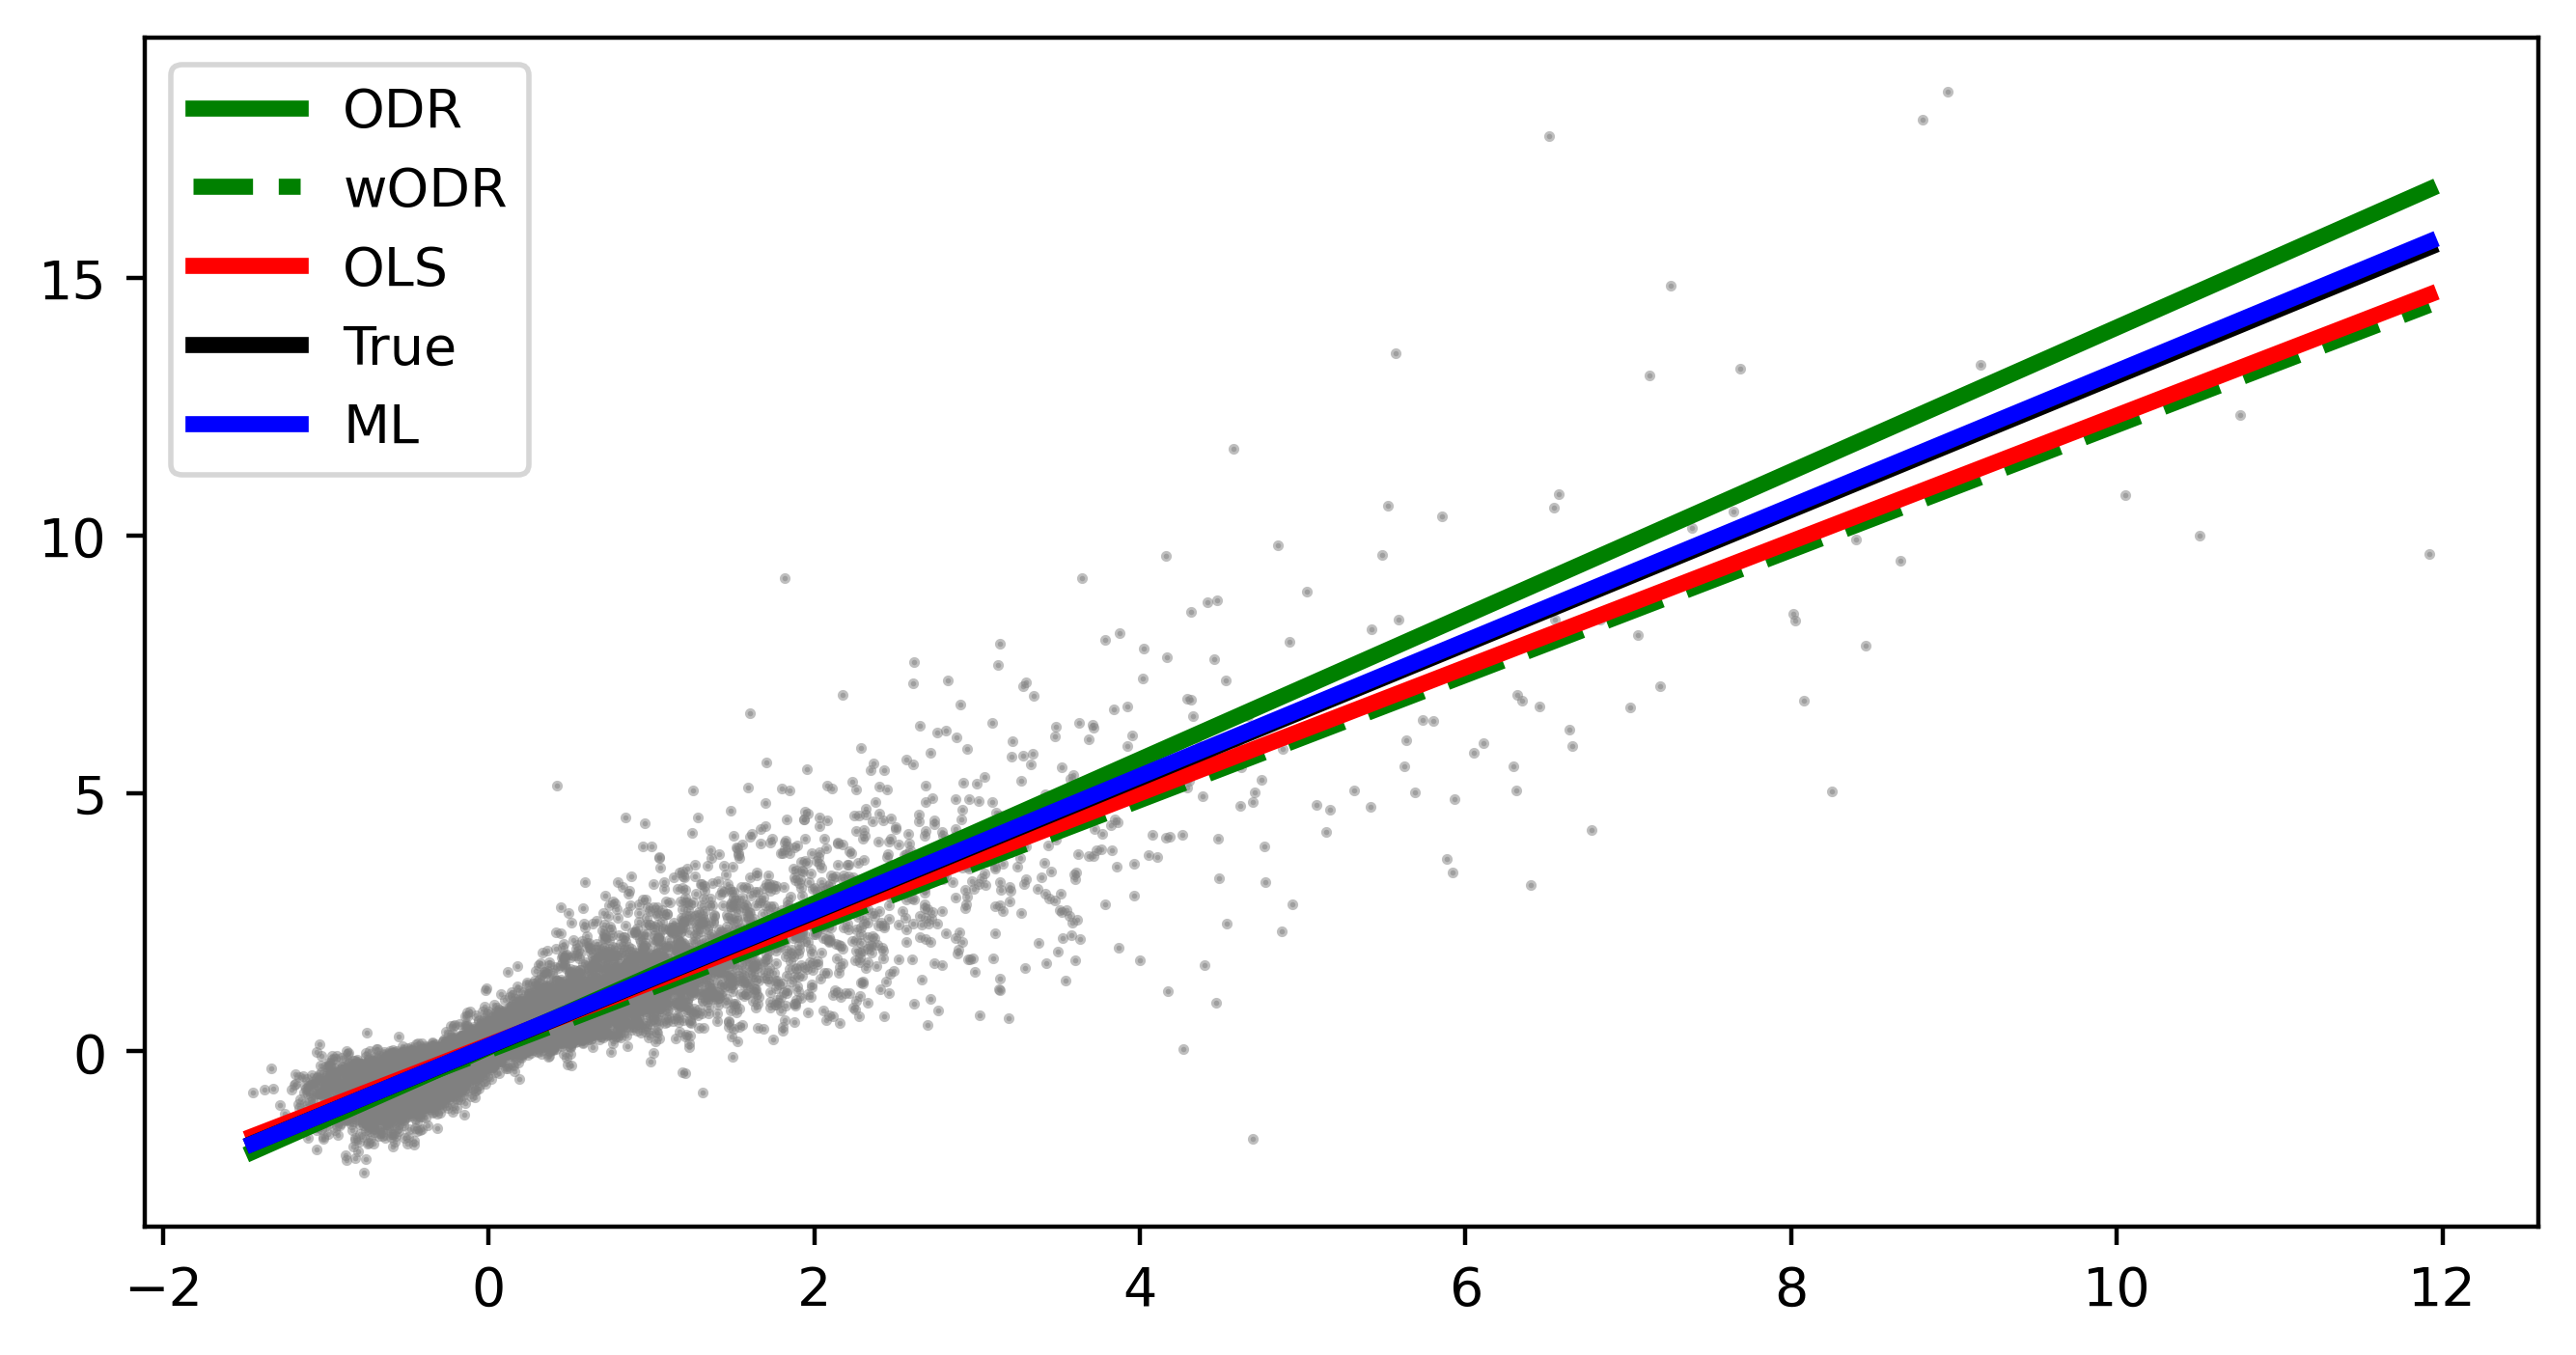

In [117]:
plt.figure(figsize=(8, 4), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(x_obs.min(), x_obs.max(), 100)
yy = k * xx + b
yy_ML = res_ML[0] * xx + res_ML[1]

plt.plot(xx, yy_ODR, color='green', label='ODR', linestyle='-', lw=3)
plt.plot(xx, yy_wODR, color='green', label='wODR', linestyle='--', lw=3)
plt.plot(xx, yy_OLS, color='red', label='OLS', linestyle='-', lw=3)
plt.plot(xx, yy, color='black', label='True', lw=3)

plt.plot(xx, yy_ML, color='blue', label='ML', linestyle='-', lw=3)

plt.legend()

### KS Based Mothod

In [119]:
regressor_logLinear_KS = RegressorLinearKS(xflow, yflow)

In [120]:
params_mean, params_std, res_arr = regressor_logLinear_KS.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

/home/jingtao/software/anaconda3/envs/rarden/lib/python3.9/site-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()


----
k: 1.305 +/- 0.086
b: 0.099 +/- 0.026
sig: 0.203 +/- 0.071
----
k: 1.287 +/- 0.087
b: 0.098 +/- 0.033
sig: 0.186 +/- 0.099
----
k: 1.296 +/- 0.084
b: 0.102 +/- 0.032
sig: 0.182 +/- 0.099
----
k: 1.293 +/- 0.092
b: 0.100 +/- 0.034
sig: 0.188 +/- 0.100
----
k: 1.289 +/- 0.088
b: 0.102 +/- 0.032
sig: 0.184 +/- 0.099
----
k: 1.289 +/- 0.087
b: 0.100 +/- 0.033
sig: 0.184 +/- 0.101
----
k: 1.289 +/- 0.089
b: 0.100 +/- 0.033
sig: 0.191 +/- 0.101
----
k: 1.289 +/- 0.091
b: 0.100 +/- 0.034
sig: 0.183 +/- 0.101
----
k: 1.289 +/- 0.090
b: 0.101 +/- 0.034
sig: 0.178 +/- 0.099
----
k: 1.292 +/- 0.084
b: 0.100 +/- 0.032
sig: 0.182 +/- 0.097
----
k: 1.288 +/- 0.086
b: 0.099 +/- 0.033
sig: 0.181 +/- 0.101
max iteration reached
[1.29023718 0.10098402 0.18061447] [0.08460853 0.03251526 0.09452342]
